In [7]:
import pandas as pd
import numpy as np
import seaborn as sn
import matplotlib.pyplot as plt

In this step, we import the necessary Python libraries for data analysis, visualization, and machine learning. These libraries help us handle datasets, create graphs, train models, and evaluate prediction results.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In this step, we load the medical insurance dataset using Pandas. The head() function displays the first five rows to get an initial overview of the dataset.

In [4]:
df = pd.read_csv("insurance.csv")

Here, we explore the dataset to understand its structure and statistical information. We check the number of rows and columns, data types, column names, and numerical summaries.

In [6]:
print(df.shape)
df.info()
print(df.describe())
print(df.columns)
print(df.dtypes)

(1337, 7)
<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   str    
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   str    
 5   region    1337 non-null   str    
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 83.6 KB
               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.663452     1.095737  13279.121487
std      14.044333     6.100468     1.205571  12110.359656
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000

In this step, we check for missing and duplicate values to improve data quality. Duplicate rows are removed, and missing values are handled using median for numerical columns and mode for categorical columns.

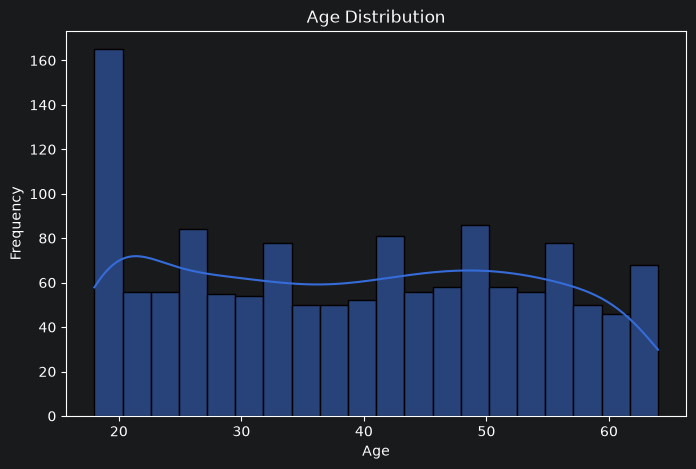

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

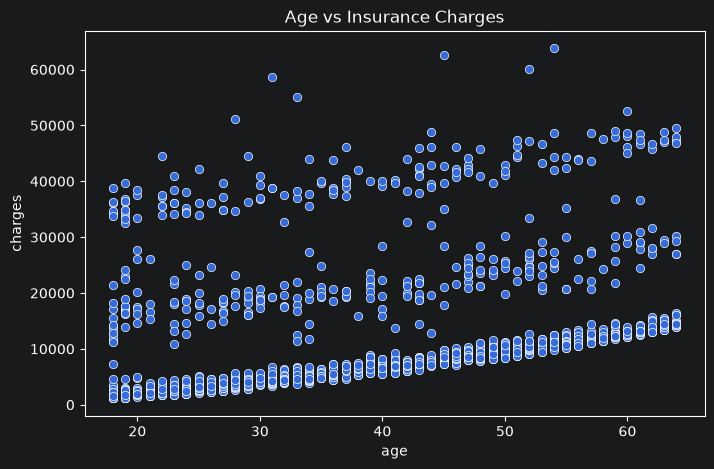

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='charges')
plt.title("Age vs Insurance Charges")
plt.show()

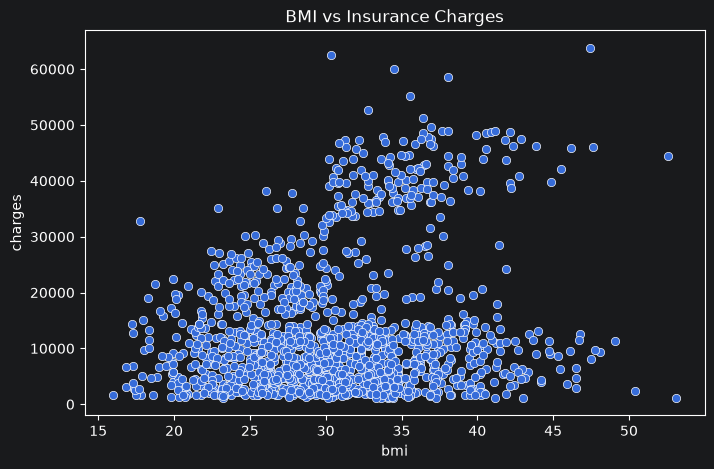

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='bmi', y='charges')
plt.title("BMI vs Insurance Charges")
plt.show()

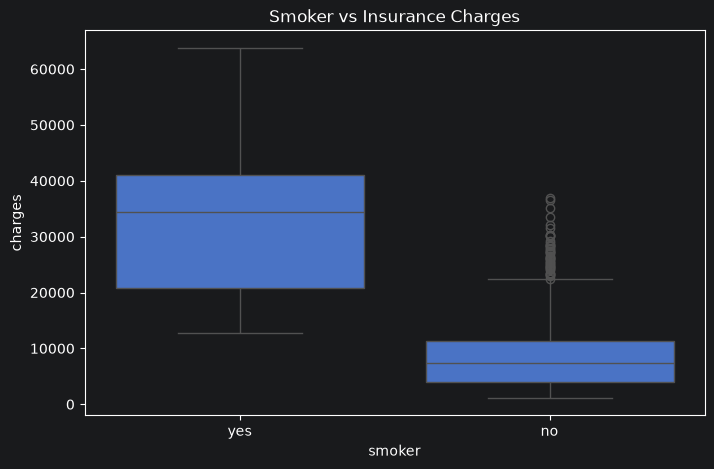

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='smoker', y='charges')
plt.title("Smoker vs Insurance Charges")
plt.show()

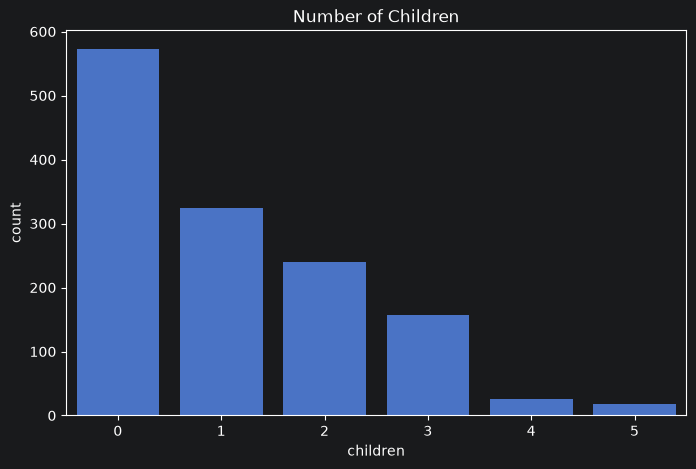

In [12]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='children')
plt.title("Number of Children")
plt.show()

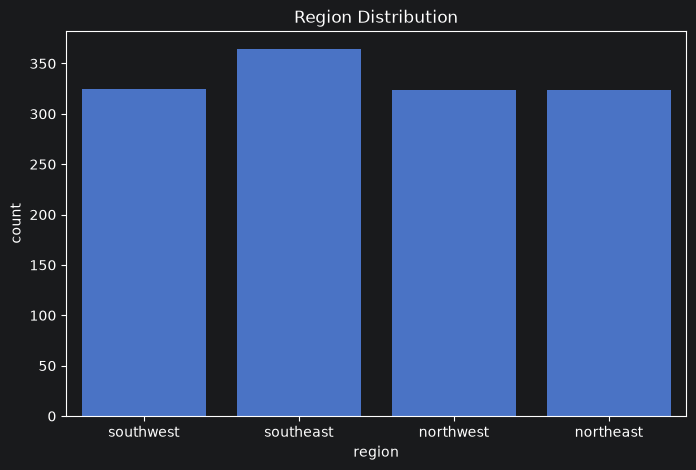

In [13]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='region')
plt.title("Region Distribution")
plt.show()

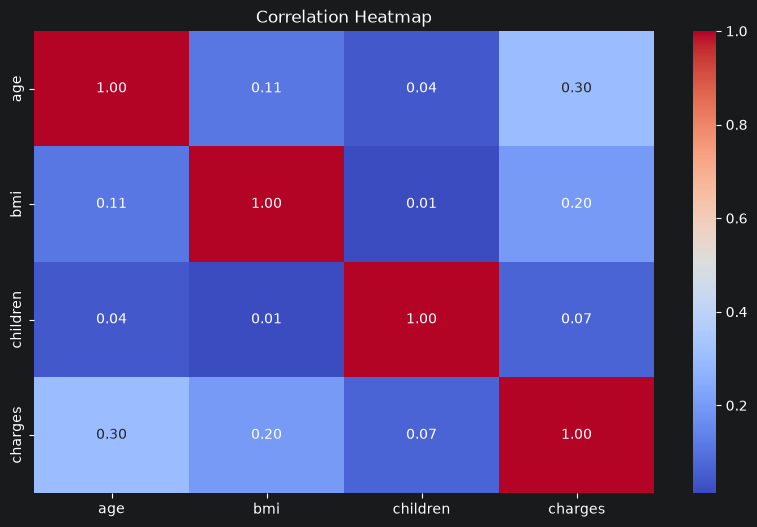

In [14]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

In [16]:
X = df.drop('charges', axis=1)
y = df['charges']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
categorical_features = ['sex', 'smoker', 'region']
numerical_features = ['age', 'bmi', 'children']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features),
        ('num', 'passthrough', numerical_features)
    ]
)

In [20]:
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

In [22]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

In [23]:
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_pred)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Linear Regression:", lr_mae, lr_mse, lr_rmse, lr_r2)
print("Random Forest:", rf_mae, rf_mse, rf_rmse, rf_r2)

Linear Regression: 4177.045561036323 35478020.67523553 5956.342894363582 0.8069287081198016
Random Forest: 2547.483611744403 21457960.354751665 4632.273778043745 0.8832258381962713


In [25]:
results = pd.DataFrame({
    'Model': ['Multiple Linear Regression',
              'Random Forest Regression'],
    'MAE': [lr_mae, rf_mae],
    'MSE': [lr_mse, rf_mse],
    'RMSE': [lr_rmse, rf_rmse],
    'R2 Score': [lr_r2, rf_r2]
})

print(results)

                        Model          MAE           MSE         RMSE  \
0  Multiple Linear Regression  4177.045561  3.547802e+07  5956.342894   
1    Random Forest Regression  2547.483612  2.145796e+07  4632.273778   

   R2 Score  
0  0.806929  
1  0.883226  


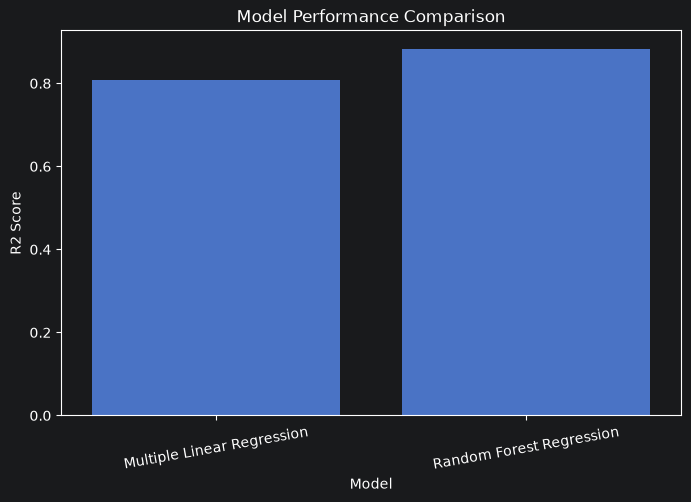

In [26]:
plt.figure(figsize=(8, 5))
sns.barplot(data=results, x='Model', y='R2 Score')
plt.title("Model Performance Comparison")
plt.xticks(rotation=10)
plt.show()

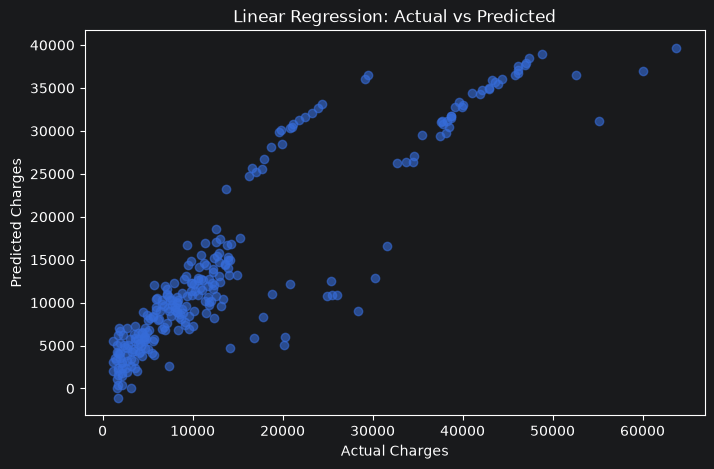

In [27]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, lr_pred, alpha=0.6)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

In [29]:
if rf_r2 > lr_r2:
    best_model = rf_model
    best_model_name = "Random Forest Regression"
else:
    best_model = lr_model
    best_model_name = "Multiple Linear Regression"

print("Best Model:", best_model_name)

Best Model: Random Forest Regression


In [31]:
new_data = pd.DataFrame({
    'age': [35],
    'sex': ['female'],
    'bmi': [28.0],
    'children': [2],
    'smoker': ['no'],
    'region': ['southeast']
})

prediction = best_model.predict(new_data)

print("Predicted Insurance Cost:", round(prediction[0], 2))

Predicted Insurance Cost: 6419.16


In [30]:
comparison = pd.DataFrame({
    'Actual Charges': y_test.values,
    'LR Predicted': lr_pred,
    'RF Predicted': rf_pred
})

print(comparison.head(10))

   Actual Charges  LR Predicted  RF Predicted
0      8688.85885   8143.693884  10040.043576
1      5708.86700   5737.115683   6493.383595
2     11436.73815  14369.314876  11592.736326
3     38746.35510  31745.513636  42111.282487
4      4463.20510   8962.386657   6035.653027
5      9304.70190  13149.722353   9597.876858
6     38511.62830  30446.760679  38429.965420
7      2150.46900   1453.288813   2143.251695
8      7345.72660  10633.018402   8759.736298
9     10264.44210  11318.943794  11220.490216
